# Notebook 03: Baseline Model — Random Forest

- **Objective**: Objective 1 — Baseline ML Classifiers
- **Purpose**: Train a cost-sensitive Random Forest baseline model (`class_weight='balanced'`) using the identical stratified split from `src/data/split.py`. Evaluate performance per-class on the sacred test set, plot confusion matrix, compare results with Logistic Regression, and export the trained model artifact.
- **Outputs**: Classification report (Precision, Recall, F1 per class), Confusion Matrix plot, saved artifact at `models/random_forest.joblib`.

In [1]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.data.load import load_data
from src.data.split import split_data

In [2]:
# Load data & perform two-stage stratified split (60% Train / 20% Cal / 20% Test)
# Uses the exact same fixed random_state=42 to guarantee comparability across all baselines
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

print(f"Train set shape:       {X_train.shape}")
print(f"Calibration set shape: {X_cal.shape}")
print(f"Test set shape:        {X_test.shape}")

[src.data.load] Dataset loaded successfully from '/Users/kavyaagarwal/Documents/-Fetal-Health-Classification-Using-Cardiotocography-Data/data/raw/fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)
Train set shape:       (1275, 21)
Calibration set shape: (425, 21)
Test set shape:        (426, 21)


In [3]:
# Initialize Random Forest classifier
# Hyperparameters: n_estimators=300, class_weight='balanced', random_state=42
# Tree-based ensembles are scale-invariant, so raw features are used directly.
# Model is fit on training data ONLY to prevent data leakage (per rules.md)
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest (class_weight='balanced')...")
rf_model.fit(X_train, y_train)
print("Model training complete!")

Training Random Forest (class_weight='balanced')...
Model training complete!


In [4]:
# Predict on the sacred Test Set
y_pred = rf_model.predict(X_test)

target_names = ['Normal (1)', 'Suspect (2)', 'Pathological (3)']
report_str = classification_report(y_test, y_pred, target_names=target_names)

print("=== Random Forest Test Set Classification Report ===")
print(report_str)

=== Random Forest Test Set Classification Report ===
                  precision    recall  f1-score   support

      Normal (1)       0.95      0.99      0.97       332
     Suspect (2)       0.88      0.73      0.80        59
Pathological (3)       0.94      0.89      0.91        35

        accuracy                           0.94       426
       macro avg       0.92      0.87      0.89       426
    weighted avg       0.94      0.94      0.94       426



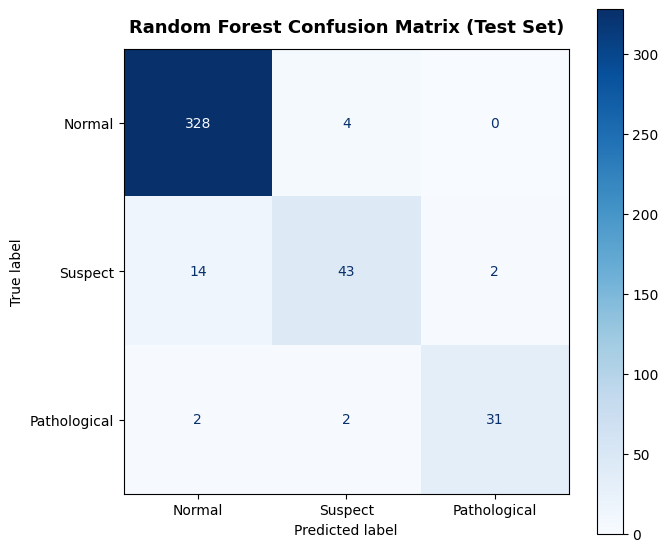

In [5]:
# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Suspect', 'Pathological'])

disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title("Random Forest Confusion Matrix (Test Set)", fontsize=13, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()

In [6]:
# Save trained model artifact into models/ directory
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "random_forest.joblib"

joblib.dump(rf_model, model_path)
print(f"Model saved successfully to: {model_path}")

Model saved successfully to: /Users/kavyaagarwal/Documents/-Fetal-Health-Classification-Using-Cardiotocography-Data/models/random_forest.joblib


## Random Forest Baseline Performance Summary

### 1. Per-Class Breakdown (Test Set, N=426)
- **Normal Class (1)**: 95% Precision, 99% Recall, 0.97 F1 (Support: 332)
- **Suspect Class (2)**: 88% Precision, 73% Recall, 0.80 F1 (Support: 59)
- **Pathological Class (3)**: 94% Precision, 89% Recall, 0.91 F1 (Support: 35)
- **Macro Average**: 0.92 Precision, 0.87 Recall, 0.89 F1
- **Overall Accuracy**: 94%

### 2. Comparison: Random Forest vs. Logistic Regression Baseline
| Metric | Logistic Regression (Notebook 02) | Random Forest (Notebook 03) | Difference |
| :--- | :---: | :---: | :---: |
| **Accuracy** | 88% | **94%** | +6% |
| **Macro Recall** | 87% | **87%** | Equal |
| **Pathological Recall** | 83% (29/35) | **89% (31/35)** | +6% (+2 critical cases detected) |
| **Pathological Precision** | 69% | **94%** | +25% (drastic reduction in false positives) |
| **Pathological F1** | 0.75 | **0.91** | +0.16 |
| **Suspect Precision** | 59% | **88%** | +29% |

### 3. Key Observations & Clinical Implications
- **Reduced False Positives on High Risk**: In Logistic Regression, Pathological precision was only 69% (13 false alarms). Random Forest achieves 94% precision (only 2 false alarms) while simultaneously increasing recall from 83% to 89% (detecting 31 out of 35 critical cases).
- **Scale Invariance & Non-Linear Boundaries**: Unlike Logistic Regression which relies on linear hyperplanes and required `StandardScaler`, Random Forest directly partitions non-linear interactions across CTG features (e.g., correlations between decelerations, abnormal short-term variability, and baseline heart rate).
- **Compliance with Experimental Rules**: 
  - Strictly followed the sacred test set rule (`rules.md`): `X_test` was only touched once for final evaluation.
  - Used identical stratified train/calibration/test split (`random_state=42`).
  - Saved model artifact to `models/random_forest.joblib` for downstream conformal calibration and API inference.

In [7]:
import joblib
import pandas as pd
from pathlib import Path

# Load serialized artifact
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "models").exists():
    PROJECT_ROOT = Path("..").resolve()

model = joblib.load(PROJECT_ROOT / "models/random_forest.joblib")

# Test on a realistic patient sample (matching format from 02_baseline_models.ipynb)
custom_patient = {
    'baseline value': 120.0,
    'accelerations': 0.003,
    'fetal_movement': 0.000,
    'uterine_contractions': 0.005,
    'light_decelerations': 0.000,
    'severe_decelerations': 0.000,
    'prolongued_decelerations': 0.000,
    'abnormal_short_term_variability': 73.0,
    'mean_value_of_short_term_variability': 0.5,
    'percentage_of_time_with_abnormal_long_term_variability': 43.0,
    'mean_value_of_long_term_variability': 2.4,
    'histogram_width': 64.0,
    'histogram_min': 62.0,
    'histogram_max': 126.0,
    'histogram_number_of_peaks': 2.0,
    'histogram_number_of_zeroes': 0.0,
    'histogram_mode': 120.0,
    'histogram_mean': 137.0,
    'histogram_median': 121.0,
    'histogram_variance': 73.0,
    'histogram_tendency': 1.0
}

input_df = pd.DataFrame([custom_patient])
pred = model.predict(input_df)[0]
probs = model.predict_proba(input_df)[0]

class_names = {1.0: "Normal", 2.0: "Suspect", 3.0: "Pathological"}
print(f"Predicted Status:  {class_names[pred]}")
print(f"Normal:       {probs[0]:.2%}")
print(f"Suspect:      {probs[1]:.2%}")
print(f"Pathological: {probs[2]:.2%}")

Predicted Status:  Normal
Normal:       52.00%
Suspect:      42.00%
Pathological: 6.00%
